#SUMMARY OF FINDINGS:

After the testing done below I've decided to use KFold Cross Validation, initially I was planning on using StratifiedKFold Validation but found it unwieldy with the requirement to split the target data into bins. I tried using y>0 as the discriminator, splitting the data into 2 bins. But the results I got weren't satisfactory. This could be due to a mistake on my part and I'm considering returning to this solution in the future if I find some better way to split the data for stratification.

Median seems like the best baseline in all aspects apart from R2 score. It's consistently got the lowest Mean Average Error.

The other models don't seem to be getting any especially notable results, all seem quite poor.

RMSE doesn't seem to give many insights into the models, all models have fairly similar values

Adding the engineered features seems to have a negative impact on all models but the median model. Further inspection may be needed.

Engineered features are calculate using the formulas defined in https://publications.gc.ca/collections/collection_2016/rncan-nrcan/Fo133-1-424-eng.pdf

In [8]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import preprocessing

from sklearn.pipeline import make_pipeline

#HYPERPARAMETERS
RANDOM_STATE = 42

In [2]:
#Read in data
df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")

categorical_columns = ["month", "day"]
numerical_columns = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

In [3]:
#Add Engineered features
#Calculations used to get BUI and FWI are based off of https://publications.gc.ca/collections/collection_2016/rncan-nrcan/Fo133-1-424-eng.pdf

def addBUI(X):
    df = X.copy()
    #BUI
    dmc = df['DMC']
    dc = df['DC']

    buiLower = (0.8*dmc*dc)/(dmc+0.4*dc)
    buiHigher = dmc-(1.0-0.8*dc/(dmc+0.4*dc))*(0.92+(0.0114*dmc)**1.7)

    bui = np.where(dmc <= 0.4*dc, buiLower, buiHigher)

    df['BUI'] = bui
    return df

def addFWI(X):
    df = X.copy()
    #FWI
    isi = df['ISI']
    bui = df['BUI']

    fdLower = 0.626*bui**0.809 + 2.0
    fdHigher = 1000.0/(25.0+108.64*np.exp(-0.023*bui))
    Fd = np.where(bui <= 80, fdLower, fdHigher)

    b = 0.1*isi*Fd
    b = np.where(b<1, 1.0, b) #Safety so that we don't try to get log(0) in the next line
    fwi = np.where(b>0.1,np.exp(2.72*(0.434*np.log(b))**0.647),b)
    
    df['FWI'] = fwi
    return df

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, OneHotEncoder, FunctionTransformer, StandardScaler
#Setting up Preprocessing Pipelines

categorical_pipe = make_pipeline(
    OneHotEncoder(handle_unknown="ignore")
)

numerical_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessing_original = make_pipeline(
    ColumnTransformer(
        [
            ("cat", categorical_pipe, categorical_columns),
            ("num", numerical_pipe, numerical_columns),
        ]
    )
)

preprocessing_all = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("cat", categorical_pipe, categorical_columns),
            ("num", numerical_pipe, numerical_columns + ["BUI", "FWI"]),
        ]
    )
)

preprocessing_fire_weather_index = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("num", numerical_pipe, ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI"]),
        ]
    )
)

# Removes Categorical data and removes DMC, DC, ISI and BUI as all are used in getting the FWI
preprocessing_very_pruned = make_pipeline(
    FunctionTransformer(addBUI),
    FunctionTransformer(addFWI),
    ColumnTransformer(
        [
            ("num", numerical_pipe, ['X', 'Y', 'FFMC', 'FWI', 'temp', 'RH', 'wind', 'rain']),
        ]
    )
)

In [5]:
from sklearn.linear_model import LinearRegression, RidgeCV, GammaRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

#Preprocessing and models that will be used

preprocessing_pipelines = {
    "ORIGINAL": preprocessing_original,
    "ALL" : preprocessing_all,
    "FIRE WEATHER INDEX ONLY": preprocessing_fire_weather_index,
    "VERY PRUNED (TEST)": preprocessing_very_pruned
}

models = {
    "Mean" : DummyRegressor(strategy="mean"),
    "Median" : DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge" : RidgeCV(alphas=[0.01,0.1,1,10,100]),
    "KNN n = 3" : KNeighborsRegressor(n_neighbors=3), # Tried changing weights to "Distance", small negative impact on results
    "KNN n = 7" : KNeighborsRegressor(n_neighbors=7),
    "KNN n = 21" : KNeighborsRegressor(n_neighbors=21),
    "Random Forest": RandomForestRegressor(max_depth=2, random_state=RANDOM_STATE),
    "Random Forest 2": RandomForestRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest 3": RandomForestRegressor(max_depth=10, random_state=RANDOM_STATE)
#    "Gamma Regressor": GammaRegressor() Doesn't work due to the 0s, normalisation fixes?
}

--------------PREPROCESSING:  ORIGINAL --------------


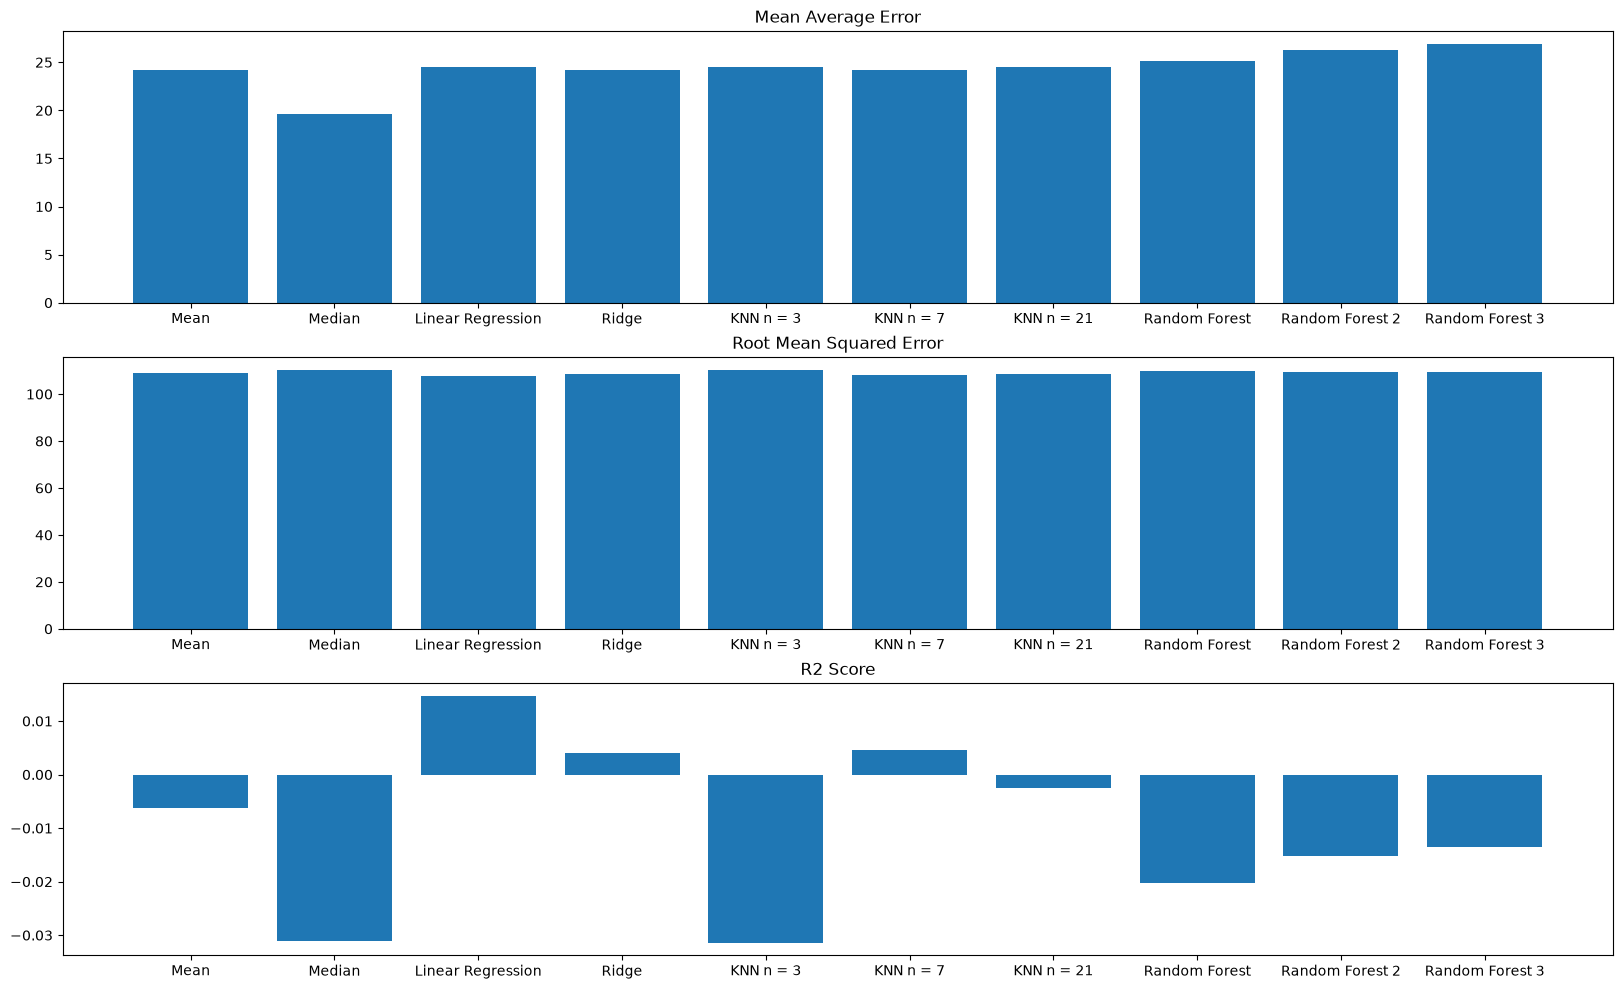

--------------PREPROCESSING:  ALL --------------


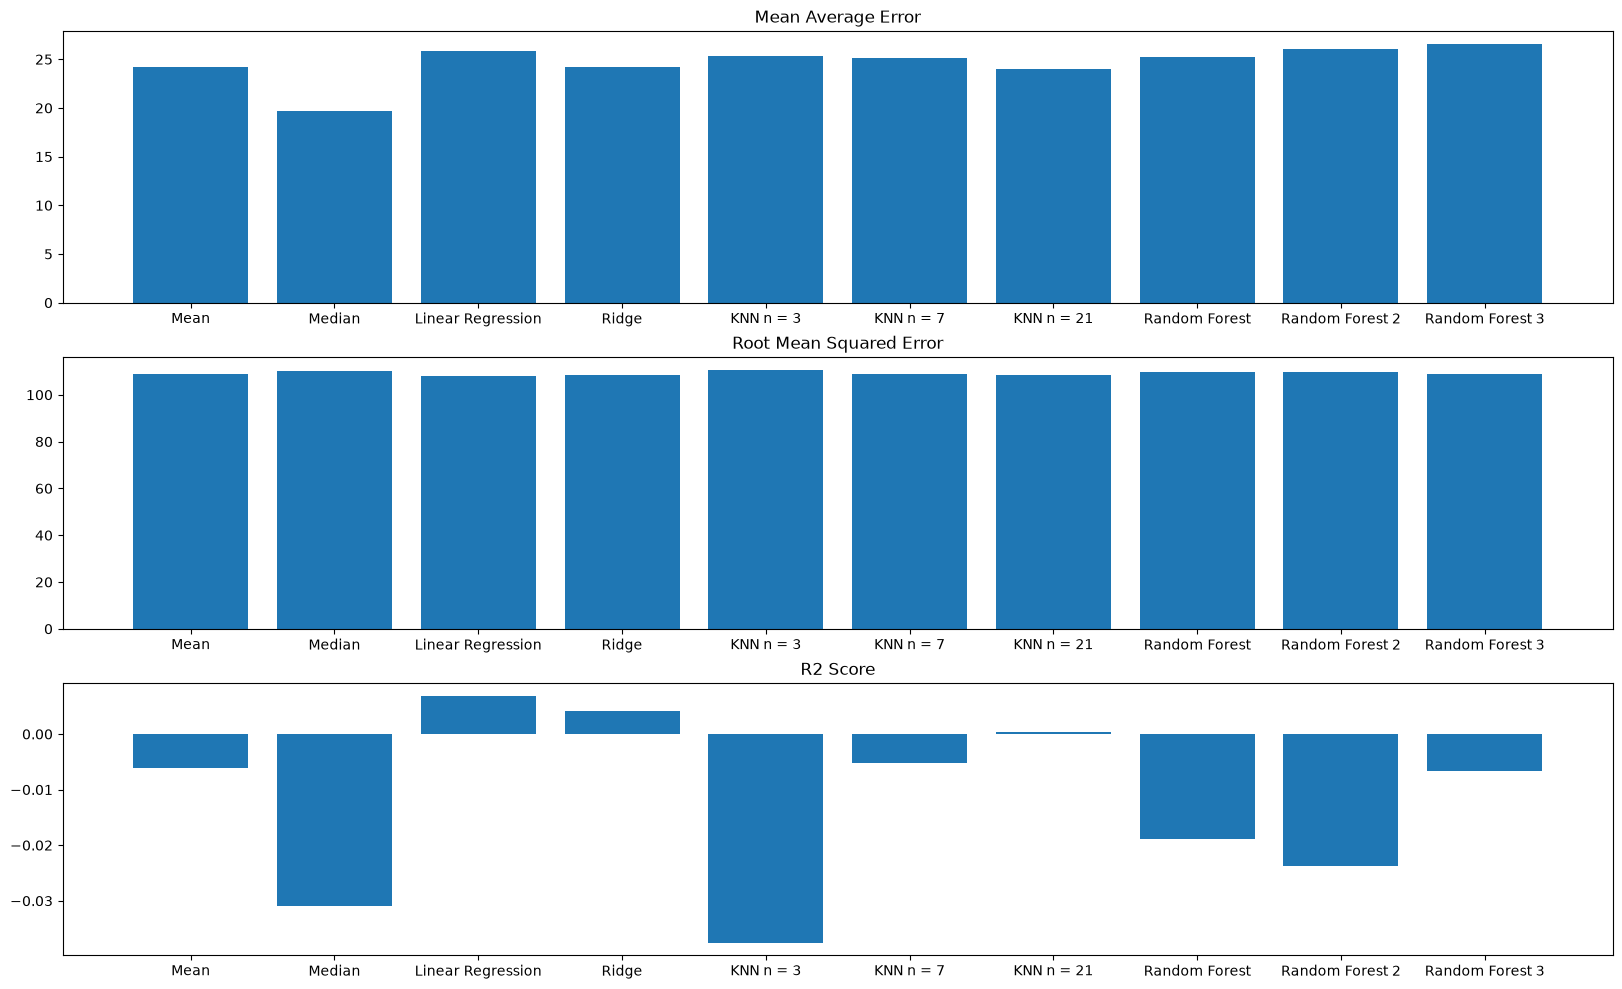

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------


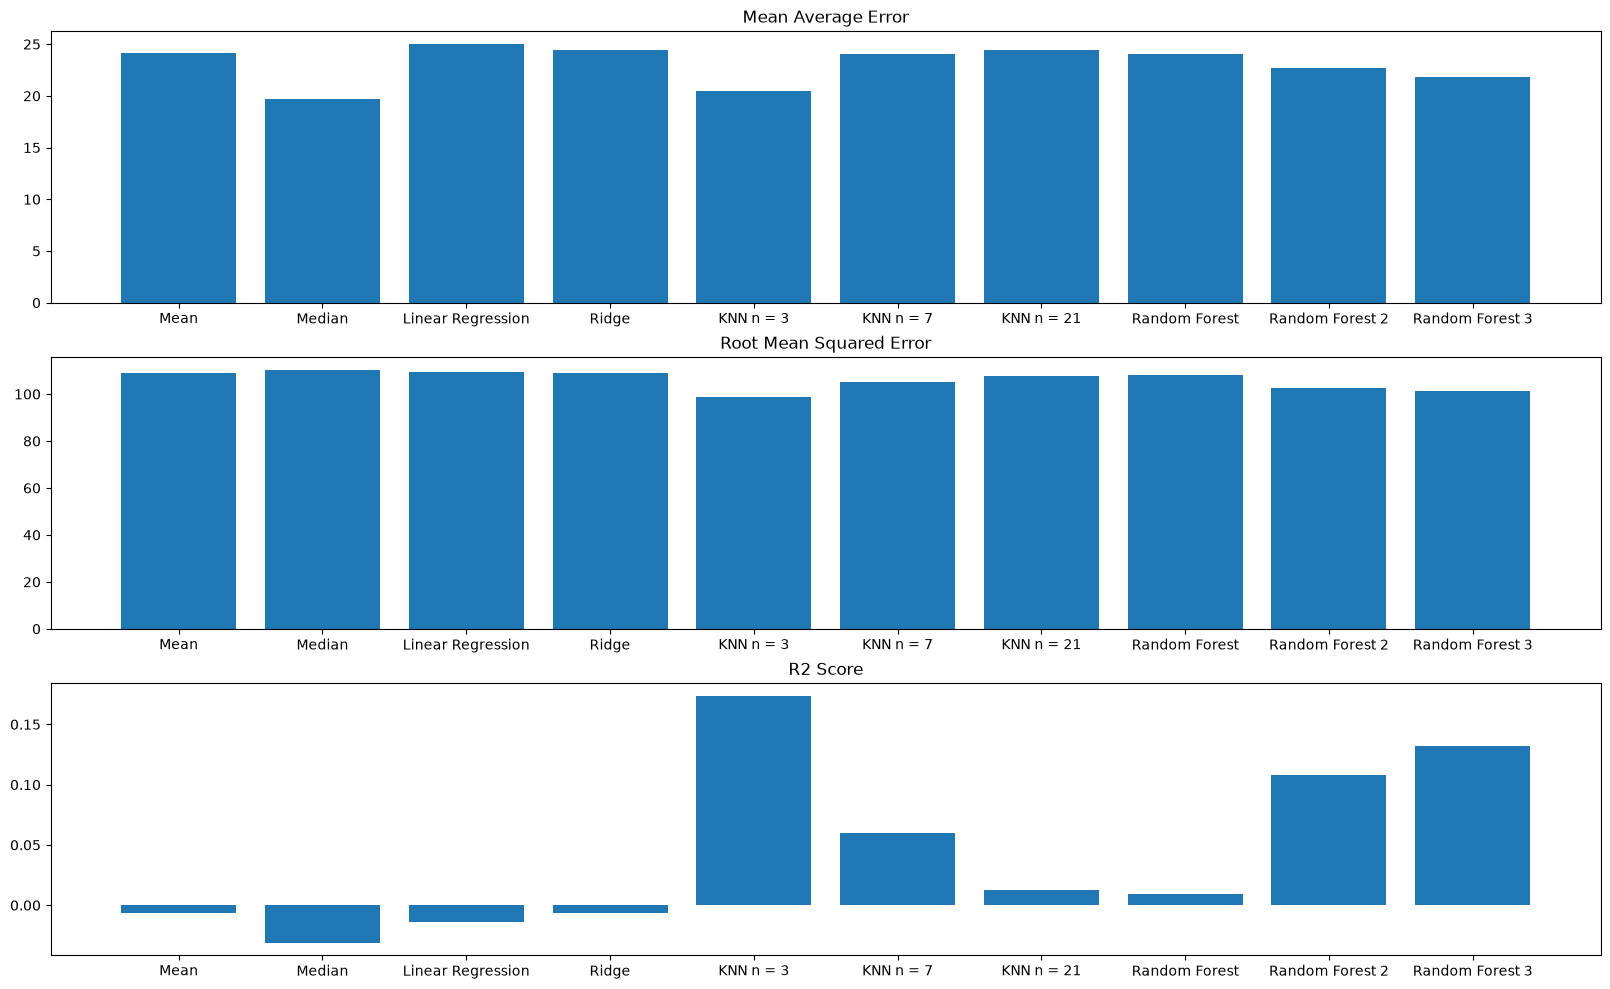

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------


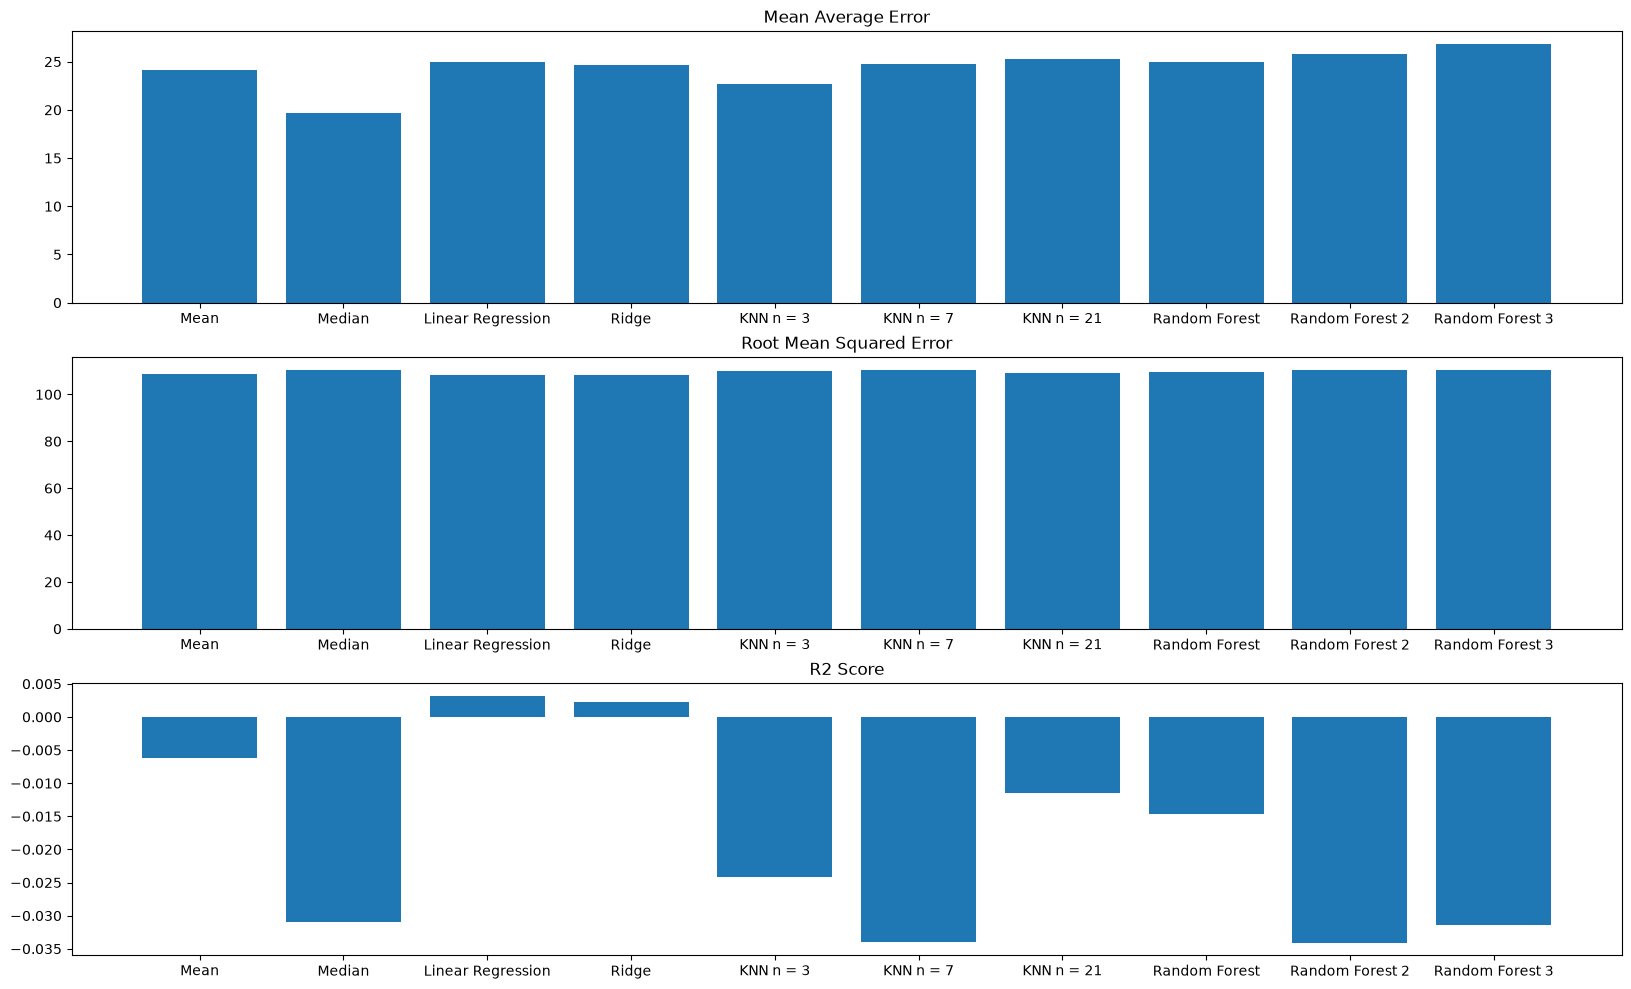

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using train test split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    # Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        #print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) ##Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()

--------------PREPROCESSING:  ORIGINAL --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  21.680605015192167 
Root Mean Squared Error:  39.88826691885835 
R2 Score:  -3.3349360817898956 


Model:  Ridge 
Mean Absolute Error:  19.52306025580642 
Root Mean Squared Error:  37.722894591089734 
R2 Score:  -2.0015700065560913 


Model:  KNN n = 3 
Mean Absolute Error:  21.745694857142855 
Root Mean Squared Error:  52.70834628999348 
R2 Score:  -16.6017315136212 


Model:  KNN n = 7 
Mean Absolute Error:  20.663277360544214 
Root Mean Squared Error:  46.40787553213491 
R2 Score:  -7.453989663889754 


Model:  KNN n = 21 
Mean Absolute Error:  20.3140165260771 
Root Mean Squared Error:  42.03533660873058 
R2 Score:

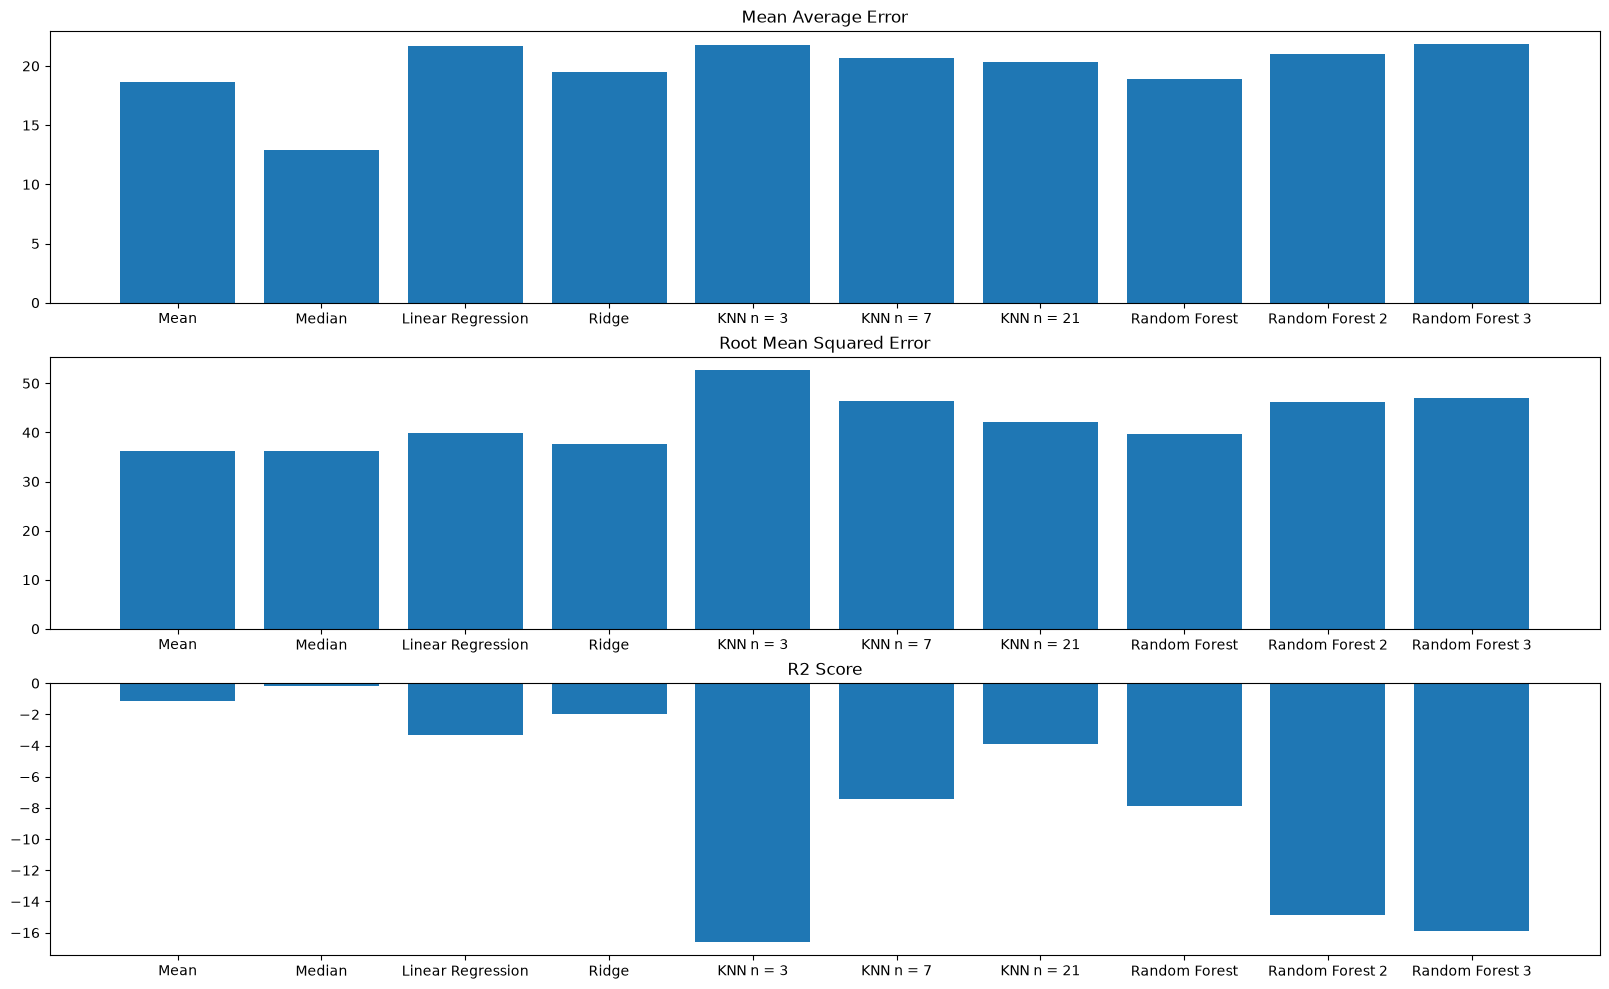

--------------PREPROCESSING:  ALL --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  21.881464293401606 
Root Mean Squared Error:  40.193303864547325 
R2 Score:  -3.5713780610189954 


Model:  Ridge 
Mean Absolute Error:  19.55729196521064 
Root Mean Squared Error:  37.76340240135969 
R2 Score:  -2.0342687317435493 


Model:  KNN n = 3 
Mean Absolute Error:  22.302227682539677 
Root Mean Squared Error:  53.81587210730052 
R2 Score:  -17.941813414878563 


Model:  KNN n = 7 
Mean Absolute Error:  20.68935058503402 
Root Mean Squared Error:  46.89419925295336 
R2 Score:  -7.731849763864954 


Model:  KNN n = 21 
Mean Absolute Error:  19.74187854875283 
Root Mean Squared Error:  40.820392201786795 
R2 Score:  

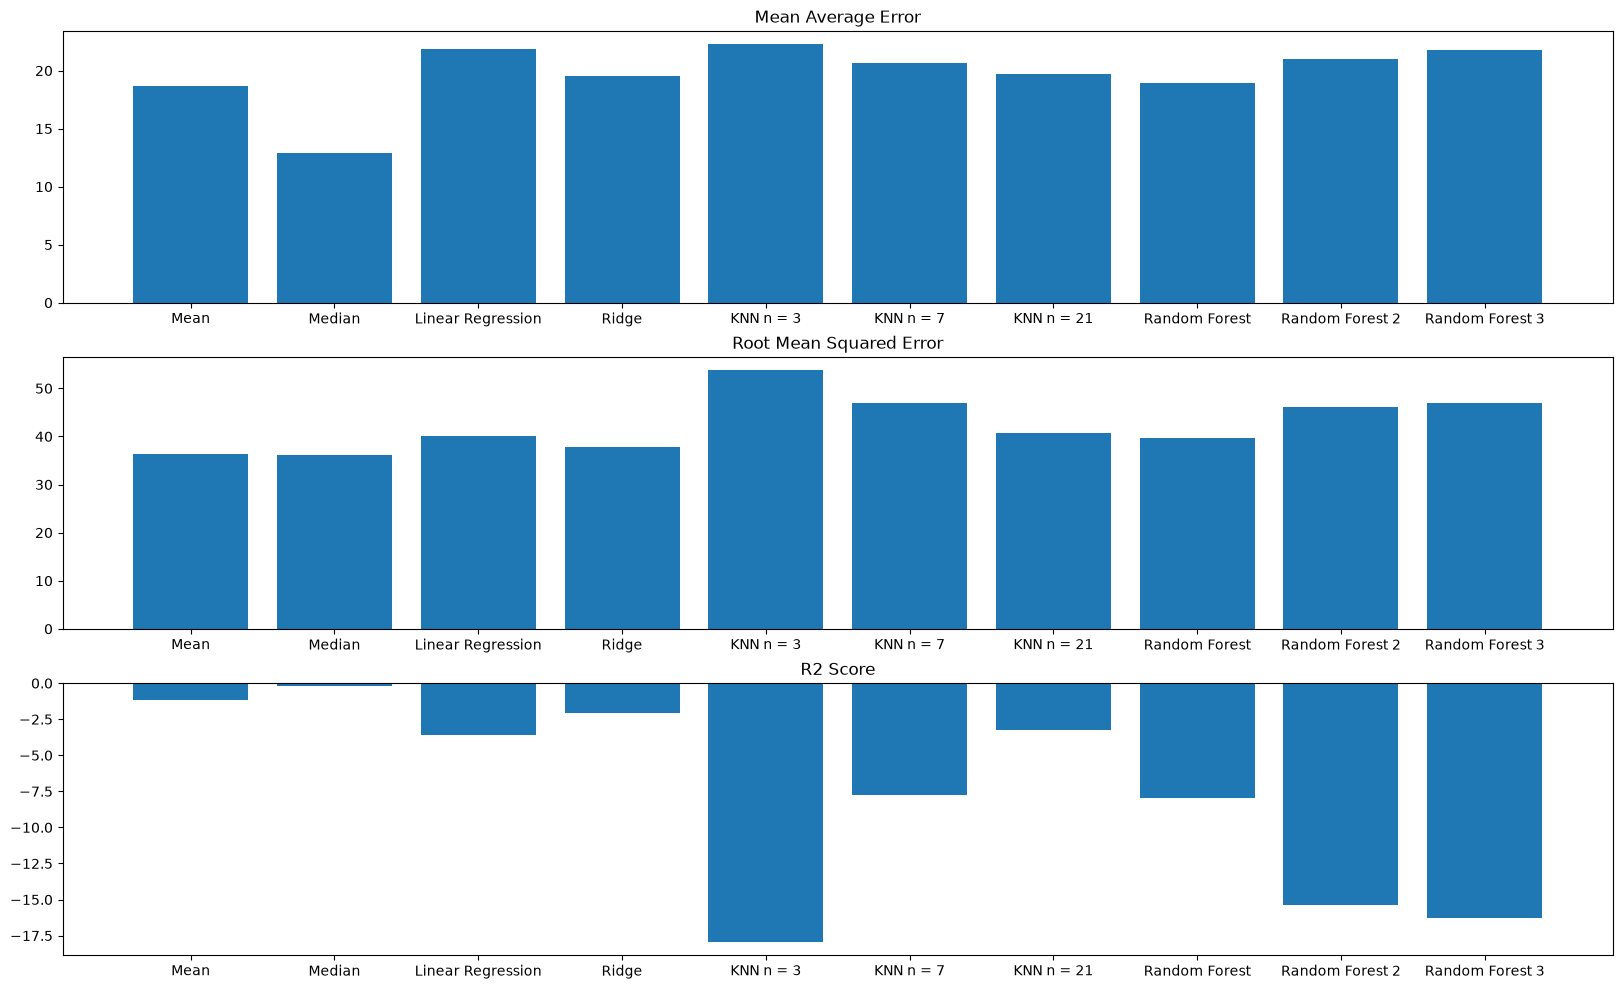

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  19.142287039658346 
Root Mean Squared Error:  36.94410661901439 
R2 Score:  -1.5303474300499313 


Model:  Ridge 
Mean Absolute Error:  18.827084593901414 
Root Mean Squared Error:  36.58478050588735 
R2 Score:  -1.3433026975646114 


Model:  KNN n = 3 
Mean Absolute Error:  20.540739999999996 
Root Mean Squared Error:  49.55327634304784 
R2 Score:  -12.17415321862406 


Model:  KNN n = 7 
Mean Absolute Error:  20.411900544217687 
Root Mean Squared Error:  45.36841533087439 
R2 Score:  -7.881034161910982 


Model:  KNN n = 21 
Mean Absolute Error:  19.300322975056687 
Root Mean Squared Error:  40.3321653

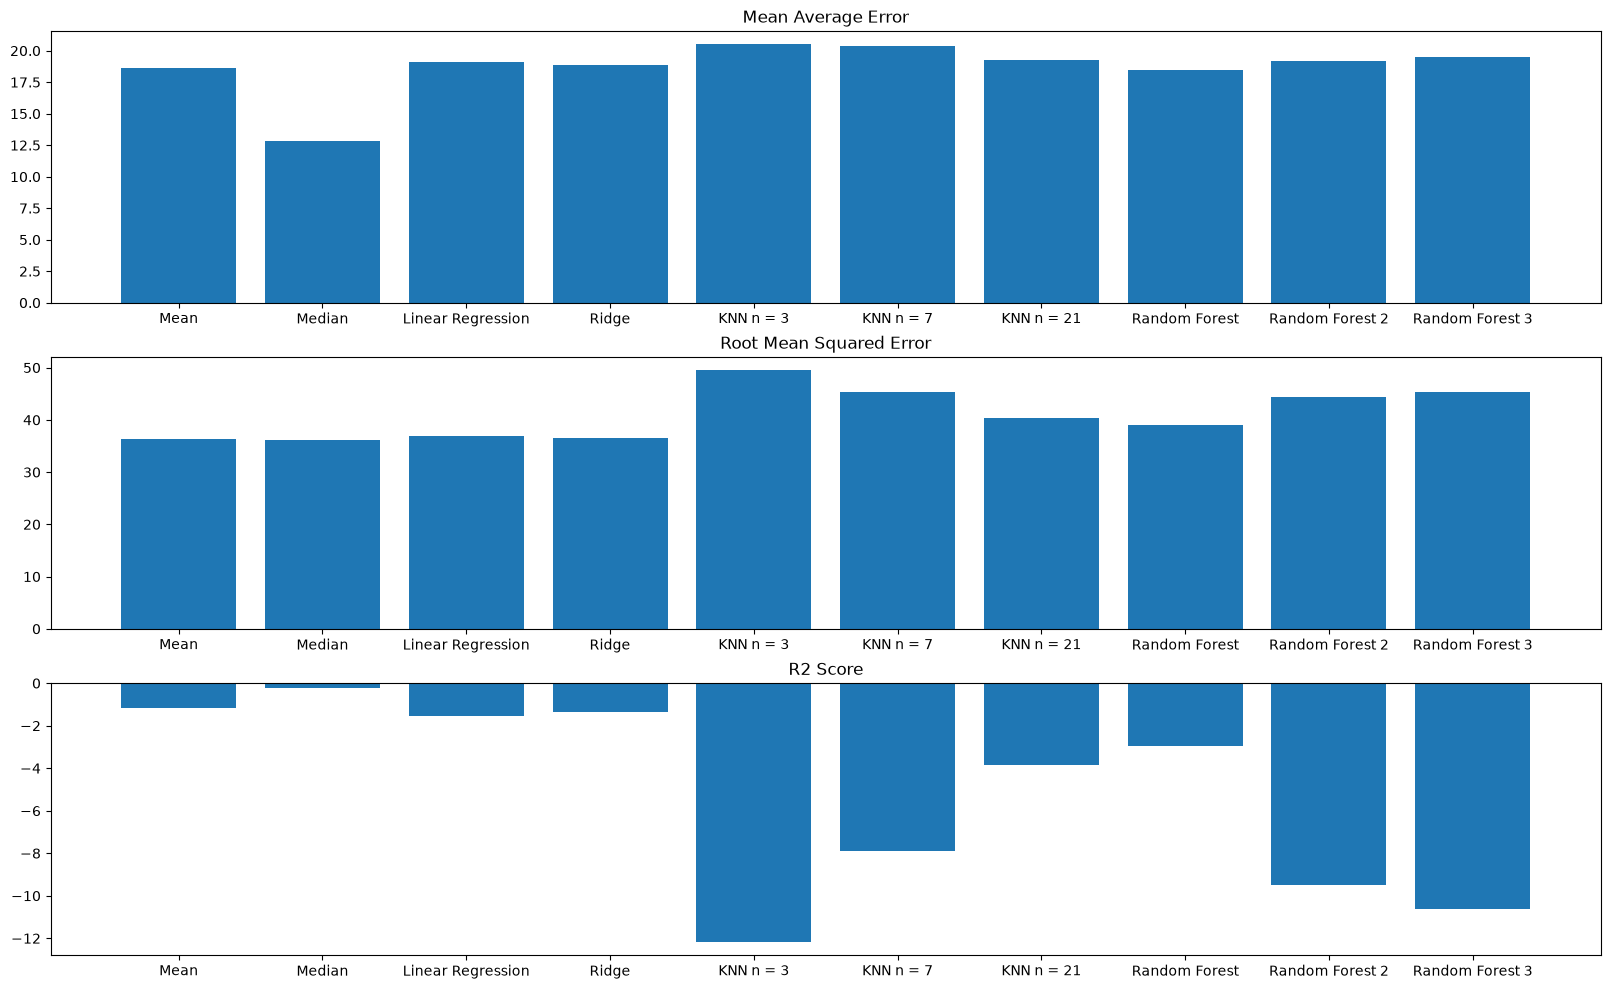

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------
Model:  Mean 
Mean Absolute Error:  18.63375593247658 
Root Mean Squared Error:  36.28115976186805 
R2 Score:  -1.1709098975511416 


Model:  Median 
Mean Absolute Error:  12.87178038095238 
Root Mean Squared Error:  36.15577891714317 
R2 Score:  -0.20736138031842005 


Model:  Linear Regression 
Mean Absolute Error:  19.757461847154573 
Root Mean Squared Error:  38.12471963556181 
R2 Score:  -2.4430780337169367 


Model:  Ridge 
Mean Absolute Error:  19.302594859292697 
Root Mean Squared Error:  37.518584855638046 
R2 Score:  -1.9559415812226664 


Model:  KNN n = 3 
Mean Absolute Error:  23.4790619047619 
Root Mean Squared Error:  55.81876107398602 
R2 Score:  -20.11768013454237 


Model:  KNN n = 7 
Mean Absolute Error:  21.586373006802717 
Root Mean Squared Error:  47.53588527540043 
R2 Score:  -7.405930300535784 


Model:  KNN n = 21 
Mean Absolute Error:  20.133584344671203 
Root Mean Squared Error:  41.6354631711361

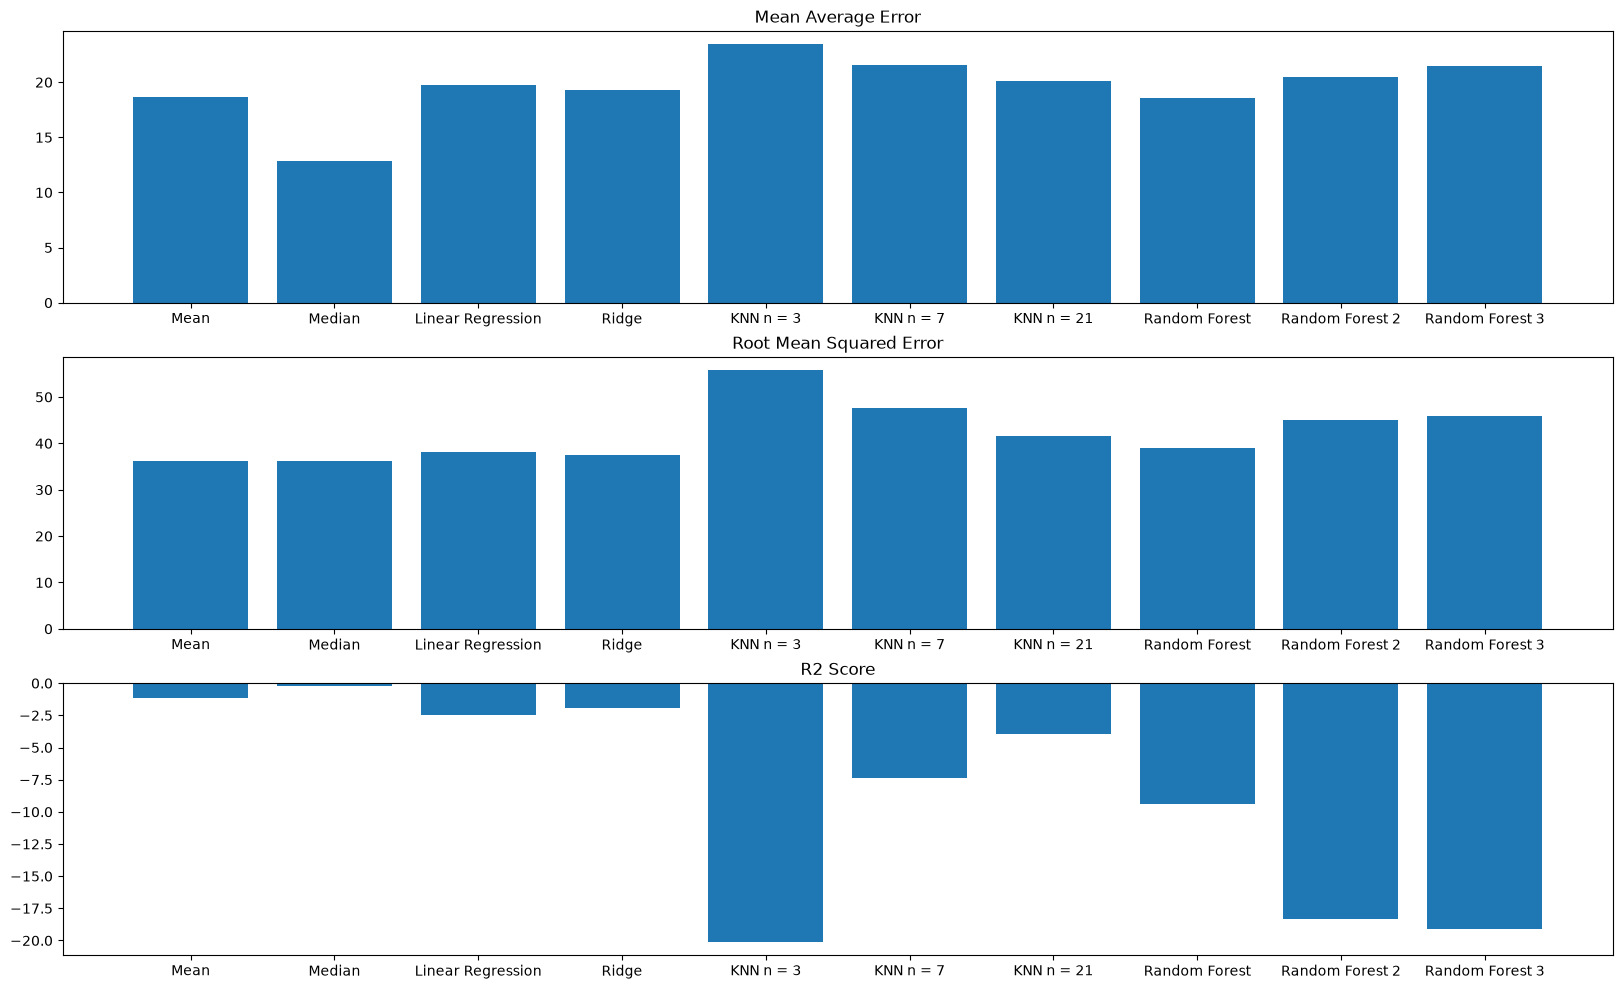

In [7]:
from sklearn.model_selection import cross_validate, RepeatedKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using cross validation

cv = RepeatedKFold(n_splits=25, n_repeats=5, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    #Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(
            preprocessing, 
            model
        )
        results = cross_validate(
            model, X, y, 
            cv=cv,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2":"r2"},
            return_train_score=False
        )

        mae = -results["test_mae"].mean()
        rmse = -results["test_rmse"].mean()
        r2 = results["test_r2"].mean()
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) #Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()